#### gaia_guery_activity_updated_dr3_v6


## How to Query and Plot data from the Gaia Sattelite Database?</h1>

Here are some useful links 
- [European Space Agency Gaia Mission - Writing Queries Turorial](https://www.cosmos.esa.int/web/gaia-users/archive/writing-queries)
- [Gaia's Hertzsprung-Russel Diagram](https://sci.esa.int/web/gaia/-/60198-gaia-hertzsprung-russell-diagram)
- [HRD with Milky Way Stars](half_a_mil/HRD_with_milky_way_stars.png)
- [Color Index](https://en.wikipedia.org/wiki/Color_index)
- [Astronomical Data in Python](https://allendowney.github.io/AstronomicalData/README.html)

In the examples below we will query ***half-a-million stars within 200 Parsecs of the sun and plot it in a Hertzsprung-Russel Diagram (HRD)***


In [1]:
#!echo $PATH  # for debugging as needed

In [2]:
# Data Folder
data_folder="data_folder"
!ls -l {data_folder}

total 19320
drwxr-xr-x 2 jupyter-boyceastro jupyter-boyceastro     4096 Feb 13  2025 archive
-rw-r--r-- 1 jupyter-boyceastro jupyter-boyceastro 12028406 Mar 31  2026 gaia-hrd-dr3-200pc_100000_stars.csv
-rw-r--r-- 1 jupyter-boyceastro jupyter-boyceastro  1195390 Mar 31  2026 gaia-hrd-dr3-200pc_10000_stars.csv
-rw-r--r-- 1 jupyter-boyceastro jupyter-boyceastro   227893 Apr  7  2026 gaia-hrd-dr3-200pc_10000_stars.csv.png
-rw-r--r-- 1 jupyter-boyceastro jupyter-boyceastro  6002060 Apr  7  2026 gaia-hrd-dr3-200pc_50000_stars.csv
-rw-r--r-- 1 jupyter-boyceastro jupyter-boyceastro   317420 Apr  7  2026 gaia-hrd-dr3-200pc_50000_stars.csv.png


In [3]:
#!pip list  # for debugging as needed

In [4]:
#EXECUTE THIS CELL THEN RESTART KERNEL
#!pip install astroquery  # for debugging as needed

In [5]:
from astroquery.utils.tap.core import TapPlus
from types import SimpleNamespace

class MirrorTap(TapPlus):
    def launch_job(self, query, *args, **kwargs):
        kwargs.setdefault("output_format", "csv")
        return super().launch_job(query, *args, **kwargs)

    def launch_job_async(self, query, *args, **kwargs):
        kwargs.setdefault("output_format", "csv")
        return super().launch_job_async(query, *args, **kwargs)

    def load_tables(self, only_names=False, include_shared_tables=False, verbose=False):
        q = "SELECT table_name FROM TAP_SCHEMA.tables"
        res = self.launch_job(q, verbose=verbose).get_results()
        return [SimpleNamespace(name=str(row["table_name"])) for row in res]

    def load_table(self, table, verbose=False):
        q = f"SELECT column_name, datatype, unit, description FROM TAP_SCHEMA.columns WHERE table_name = '{table}'"
        res = self.launch_job(q, verbose=verbose).get_results()
        cols = [SimpleNamespace(name=str(r["column_name"]), data_type=str(r["datatype"]),
                                unit=str(r["unit"]), description=str(r["description"])) for r in res]
        return SimpleNamespace(name=table, columns=cols)

mirrors = [
    ("ARI Heidelberg", "https://" + "gaia.ari.uni-heidelberg.de/tap"),
    ("AIP Potsdam", "https://" + "gaia.aip.de/tap"),
]

Gaia = None
tables = []

for name, url in mirrors:
    try:
        print(f"Trying {name} ({url})...")
        candidate = MirrorTap(url=url)
        tables = candidate.load_tables(only_names=True)
        Gaia = candidate
        print(f"Connected successfully to {name}!\n")
        break
    except Exception as e:
        print(f"Failed to connect to {name}: {e}\n")

if Gaia is None:
    raise RuntimeError("Could not connect to any Gaia TAP mirror.")

# Print the Table Names in the Gaia Database
for table in tables:
    print(table.name)


Trying ARI Heidelberg (https://gaia.ari.uni-heidelberg.de/tap)...
Connected successfully to ARI Heidelberg!

TAP_SCHEMA.schemas
TAP_SCHEMA.tables
TAP_SCHEMA.columns
TAP_SCHEMA.keys
TAP_SCHEMA.key_columns
tycho2
ppmxl
twomass
gaiadr1.cepheid
gaiadr1.phot_variable_time_series_gfov
gaiadr1.aux_qso_icrf2_match
gaiadr1.tgas_source
hipparcos
gaiadr1.rrlyrae
gaiadr1.phot_variable_time_series_gfov_statistical_parameters
gaiadr1.variable_summary
gaiadr1.gaia_source
ivoa.ObsCore
gaiadr2.ruwe
gaiadr2_complements.geometric_distance
gaiadr2.vari_long_period_variable
gaiadr2.allwise_neighbourhood
gaiadr2.apassdr9_best_neighbour
gaiadr2.hipparcos2_best_neighbour
gaiadr2.aux_sso_orbits
gaiadr2.vari_cepheid
gaiadr2.vari_time_series_statistics
gaiadr2.vari_rotation_modulation
gaiadr2.vari_classifier_result
gaiadr2.vari_classifier_class_definition
gaiadr2.sso_source
gaiadr2.gaia_source
gaiadr2.aux_iers_gdr2_cross_id
gaiadr2.vari_rrlyrae
gaiadr2.allwise_best_neighbour
gaiadr2.vari_short_timescale
gaiadr2.

In [6]:
# Get Gaia Sources Table
meta = Gaia.load_table('gaiadr3.gaia_source')
print(meta)

namespace(name='gaiadr3.gaia_source', columns=[namespace(name='non_single_star', data_type='SMALLINT', unit='--', description='Flag indicating the availability of additional information in the various Non-Single Star tables'), namespace(name='ag_gspphot', data_type='REAL', unit='mag', description='Extinction in G band from GSP-Phot Aeneas best library using BP/RP spectra'), namespace(name='astrometric_excess_noise', data_type='REAL', unit='mas', description='Excess noise of the source'), namespace(name='astrometric_excess_noise_sig', data_type='REAL', unit='--', description='Significance of excess noise'), namespace(name='astrometric_n_good_obs_al', data_type='SMALLINT', unit='--', description='Number of good observations in the along-scan (AL) direction'), namespace(name='astrometric_n_obs_al', data_type='SMALLINT', unit='--', description='Total number of observations in the along-scan (AL) direction'), namespace(name='classprob_dsc_combmod_galaxy', data_type='REAL', unit='--', descri

In [7]:
# Print all columns in the Gaia Source Table
for column in meta.columns:
    print(column.name)

non_single_star
ag_gspphot
astrometric_excess_noise
astrometric_excess_noise_sig
astrometric_n_good_obs_al
astrometric_n_obs_al
classprob_dsc_combmod_galaxy
classprob_dsc_combmod_quasar
dec_parallax_corr
dec_pseudocolour_corr
distance_gspphot_lower
distance_gspphot_upper
ebpminrp_gspphot_lower
ebpminrp_gspphot_upper
ipd_frac_odd_win
ipd_gof_harmonic_amplitude
logg_gspphot_lower
logg_gspphot_upper
matched_transits_removed
mh_gspphot_lower
mh_gspphot_upper
new_matched_transits
nu_eff_used_in_astrometry
parallax_error
parallax_pmdec_corr
parallax_pseudocolour_corr
phot_bp_mean_flux
phot_bp_mean_mag
phot_bp_rp_excess_factor
phot_g_mean_mag
phot_rp_mean_mag
pm
pmdec
pmdec_error
pmdec_pseudocolour_corr
pmra
pmra_error
pmra_pseudocolour_corr
ra_dec_corr
ra_parallax_corr
ra_pmdec_corr
ra_pmra_corr
ra_pseudocolour_corr
ruwe
rv_atm_param_origin
rv_method_used
rv_nb_deblended_transits
rv_template_fe_h
rv_template_logg
rv_template_teff
rv_time_duration
rv_visibility_periods_used
scan_direction_mea

In [8]:
# Create a Synchronous (immediate submit) Query Job 
# for just the top 10 rows from the table retrieving
# columns source_id, ra, dec, parallax (How did I know the column names ??)
# note that it validates and gives you the units, description and bad rows!
query1 = """SELECT 
TOP 10
source_id, ra, dec, parallax 
FROM gaiadr3.gaia_source
"""
job1 = Gaia.launch_job(query1)
job1
print(job1)

<Table length=10>
   name    dtype     class     n_bad
--------- ------- ------------ -----
source_id   int64       Column     0
       ra float64       Column     0
      dec float64       Column     0
 parallax float64 MaskedColumn     1
Jobid: None
Phase: COMPLETED
Owner: None
Output file: sync_20261126033105.csv
Results: None


In [9]:
print(query1)

SELECT 
TOP 10
source_id, ra, dec, parallax 
FROM gaiadr3.gaia_source



In [10]:
# This statement below retrieves the result (note only 10 rows retrieved because that is what we asked for!)
results = job1.get_results()
results

source_id,ra,dec,parallax
int64,float64,float64,float64
5942876222331557376,248.4176248201387,-46.498792992644454,0.988732772034142
5942876222331614080,248.41995576431168,-46.491708139540485,0.19800385342655344
5942876226657046528,248.41817669126806,-46.50079671118401,0.8873591950041683
5942876226657063296,248.41571192744092,-46.49721031230395,0.09994344779175135
5942876226657071360,248.41298915120962,-46.49573374493849,0.5667589521702036
5942876226657075072,248.41734109723012,-46.49238683465431,0.10656644142274802
5942876226657084800,248.41376993347922,-46.49107838437496,0.6474059644231992
5942876226657092480,248.4118471329973,-46.49058562940238,--
5942876226657098112,248.4148586975572,-46.487372622359985,0.11082348629810175


In [11]:
# Create a Asynchronous (scheduled submit) Query Job
# for just the top 2000 rows from the table retrieving
# columns source_id, ra, dec, pmra, pmdec, parallax, bp_rp 
# with a WHERE clause
# note that it validates and gives you the units, description and bad rows!
# What does Parallax < 1 mean in terms of distance ??  d = 1/p
query2 = """SELECT 
TOP 2000
source_id, ra, dec, pmra, pmdec, parallax, phot_g_mean_mag, 1000/parallax as dist, bp_rp
FROM gaiadr3.gaia_source
WHERE parallax > 5.0 AND parallax < 6.666667
"""
job2 = Gaia.launch_job(query2)  # synchronous is instant for <= 2000 rows
print(job2)



<Table length=2000>
      name       dtype     class     n_bad
--------------- ------- ------------ -----
      source_id   int64       Column     0
             ra float64       Column     0
            dec float64       Column     0
           pmra float64       Column     0
          pmdec float64       Column     0
       parallax float64       Column     0
phot_g_mean_mag float64 MaskedColumn     7
           dist float64       Column     0
          bp_rp float64 MaskedColumn   290
Jobid: None
Phase: COMPLETED
Owner: None
Output file: sync_20261126033105.csv
Results: None


In [12]:
# This statement below retrieves the result (note 2000 rows retrieved because that is what we asked for!)
results = job2.get_results()
results

source_id,ra,dec,pmra,pmdec,parallax,phot_g_mean_mag,dist,bp_rp
int64,float64,float64,float64,float64,float64,float64,float64,float64
4165071645134231936,264.94950714988306,-9.526975348214133,19.845018422780548,1.938149542673907,5.000000067713205,20.427282,199.99999729147186,2.499939
4078365365086028416,280.2970306991858,-23.435446238130844,-8.395027265550313,-6.375870691228341,5.000000079785925,20.121367,199.99999680856303,1.4665661
4053338796833458304,264.14062209255724,-34.822010173107806,0.6109569666798426,-1.7286522266699516,5.000000516133637,20.15942,199.99997935465663,--
6000271833111039744,229.04075287708758,-44.67343331152408,6.288372026267793,-5.347916299923282,5.000000564084334,20.677351,199.9999774366292,1.8952694
85457892001872000,42.2735201025002,21.238497470585106,-45.11685338538362,-41.22274889845018,5.0000013386678415,18.027079,199.99994645330068,2.4856224
6702268805824338304,274.92203531022653,-50.97719306611556,10.508906828042466,-15.458734733228184,5.00000137946455,11.918877,199.99994482143325,0.9670067
4043636981083110400,268.6948226391288,-31.938008617859957,-9.435359824172943,-5.098344146178308,5.000001462655443,19.957098,199.99994149379938,--
5980297005418931456,258.5566114967589,-32.19882446819251,-2.1872890922830455,-8.016647654609347,5.000001505589202,19.165562,199.99993977645008,1.5284843
2295269559942880128,294.0565011897345,80.95385888383557,15.620527998588454,10.20848073222741,5.000002323984963,14.040513,199.9999070406447,1.6762905


In [13]:
print(results["parallax"], results["phot_g_mean_mag"],results["bp_rp"])

     parallax     
------------------
 5.000000067713205
 5.000000079785925
 5.000000516133637
 5.000000564084334
5.0000013386678415
  5.00000137946455
 5.000001462655443
 5.000001505589202
 5.000002323984963
 5.000002469106699
               ...
 5.000647057419984
 5.000647382342161
 5.000647844897986
 5.000648242962972
 5.000648298945491
 5.000648370625414
 5.000648964477057
 5.000649584887203
 5.000650047975499
 5.000650089406914
Length = 2000 rows phot_g_mean_mag
---------------
      20.427282
      20.121367
       20.15942
      20.677351
      18.027079
      11.918877
      19.957098
      19.165562
      14.040513
      18.142717
            ...
      20.208202
      20.859812
      19.423729
      20.663265
      19.026024
      20.204582
      17.380156
      19.411276
      19.615152
      19.964472
Length = 2000 rows   bp_rp  
---------
 2.499939
1.4665661
       --
1.8952694
2.4856224
0.9670067
       --
1.5284843
1.6762905
       --
      ...
 2.021389
0.9536457
2.80685

In [14]:
# Calculate absolute magnitude with parallax in mas
# Make sure parallax > 0 by creating another filter

import numpy as np # for log10() function

distance_modulus = -5 * np.log10(results['parallax']) + 10
abs_mag = results['phot_g_mean_mag'] - distance_modulus
bp_rp = results['bp_rp']

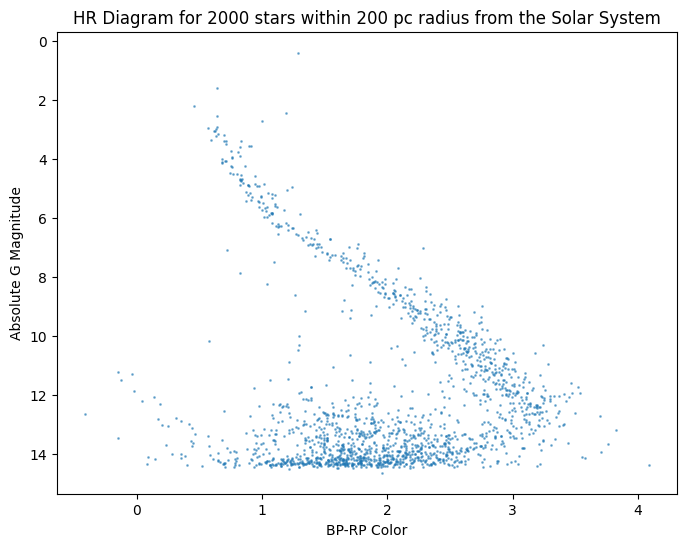

In [15]:
# plot the H-R diagram for the 2000 stars within 200 pc radius from the Solar System
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(bp_rp, abs_mag, s=1, alpha=0.5)
plt.gca().invert_yaxis()
plt.xlabel("BP-RP Color")
plt.ylabel("Absolute G Magnitude")
plt.title(f"HR Diagram for 2000 stars within 200 pc radius from the Solar System")
plt.show()

In [16]:
def send_radial_gaia_query(query_size=500, distance=200, **kwargs):
    min_parallax = 1000.0 / distance
    query3 = (
        f" SELECT TOP {query_size}"
        " source_id, ra, dec, parallax, bp_rp, phot_g_mean_mag+5*log10(parallax)-10 as mg, 1000/parallax as dist"
        " FROM gaiadr3.gaia_source"
        f" WHERE parallax >= {min_parallax}"
        " AND bp_rp > -0.75"
        " AND bp_rp < 6"
        " AND visibility_periods_used > 8"
        " AND phot_g_mean_flux_over_error > 50"
        " AND phot_bp_mean_flux_over_error > 20"
        " AND phot_rp_mean_flux_over_error > 20"
        " AND phot_bp_rp_excess_factor < 1.3+0.06*power(phot_bp_mean_mag-phot_rp_mean_mag,2)"
        " AND phot_bp_rp_excess_factor > 1.0+0.015*power(phot_bp_mean_mag-phot_rp_mean_mag,2)"
        " AND astrometric_chi2_al/(astrometric_n_good_obs_al-5) < 1.44*greatest(1,exp(-0.4*(phot_g_mean_mag-19.5)))"
    )
    # Synchronous execution avoids the mirror's slow async queue and supports dump_to_file
    return Gaia.launch_job(query3, **kwargs)


In [17]:
job3 = send_radial_gaia_query(query_size=10000,distance=200)  # Query 10000 alhough default is 500 stars
results = job3.get_results()
results

source_id,ra,dec,parallax,bp_rp,mg,dist
int64,float64,float64,float64,float64,float64,float64
6702268805824338304,274.92203531022653,-50.97719306611556,5.00000137946455,0.9670067,5.413727268723072,199.99994482143325
2295269559942880128,294.0565011897345,80.95385888383557,5.000002323984963,1.6762905,7.535364069608956,199.9999070406447
4943141327700869888,32.495089511003954,-46.261405429797136,5.00000340527564,0.82109356,4.685763747276113,199.99986378906715
6806584735284468864,310.44941038191746,-23.89095211881626,5.00000371477032,2.7497654,11.008943126682965,199.9998514092976
147678675197944064,70.1824473816469,24.568284297925977,5.000005747939695,2.757125,8.981028055086526,199.99977008267652
5931076920762151296,249.36245678935475,-52.437960608215725,5.000008157145059,1.7800732,7.96864850141408,199.99967371472997
375954743871676160,13.16836621656084,44.11515734245674,5.000011359671689,1.4674101,6.96863081876468,199.9995456141648
270623557158662144,64.30926343005594,50.10101068783158,5.000013203931727,2.4740353,10.19713007857698,199.99947184412568
2019316571182734848,292.61695313663677,22.398490577269538,5.000013539714383,2.053256,8.563342115579456,199.99945841289127


In [18]:
mg = results["mg"]
bp_rp = results["bp_rp"]

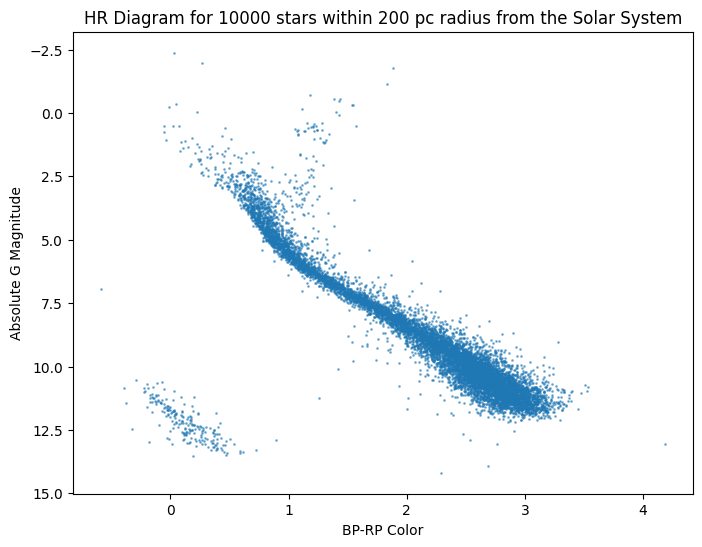

In [19]:
# plot the H-R diagram for the 10000 stars within 200 pc radius from the Solar System
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(bp_rp, mg, s=1, alpha=0.5)
plt.gca().invert_yaxis()
plt.xlabel("BP-RP Color")
plt.ylabel("Absolute G Magnitude")
plt.title(f"HR Diagram for 10000 stars within 200 pc radius from the Solar System")
plt.show()

In [ ]:
# sun's HRD coordinates values for plotting
#     google "what is bp-rp of the sun" bp-rp = 0.82
bp_rp_sun = ??

#     we calculated the abs mag of the sun in the "brightness of stars" project
#     we will do it again below:
sun_app_mag = ?? # very very bright in the sky!
sun_dist_km = ?? #km
light_speed = ?? #km/s
seconds_in_a_year = ??
light_year_km =  ??
parsec_km = ?? #km/pc
sun_dist_pc = ??

# Use the magnitude formula above to calculate the absolute magnitude of the Sun
sun_abs_mag = ??
#print(sun_abs_mag)

In [ ]:
# plot the H-R diagram for the 10000 stars within 200 pc radius from the Solar System
# Also plot the Sun using the plt.scatter() method!
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(??)
plt.scatter(??) # Plot the HRD

plt.scatter(??, ??, marker='+', color="red") # plot a single cross for the sun
plt.text(bp_rp_sun+0.2, sun_abs_mag, "Red Cross is our Sun!",  color="red")

plt.gca().invert_yaxis()
plt.xlabel("BP-RP Color")
plt.ylabel("Absolute G Magnitude")
plt.title(f"HR Diagram for 10000 stars within 200 pc radius from the Solar System")
plt.show()

In [ ]:
!ls -l data_folder

In [ ]:
# Here I am defining a job for the same asynchronous within a try-except block
# This will first look for a previoysly stored file (try-block)
# if it does not exist it will execute the query (except-bloclk)

import numpy as np
from astropy import log

num_stars = 10000
small_datafile_name = data_folder+"/gaia-hrd-dr3-200pc_%d_stars.csv" % (num_stars)
try:
    log.info(f"Getting the DR3 results on nearby (d < 200 pc) stars stored in {small_datafile_name}\n")
    #gaiarec = np.recfromcsv(small_datafile_name)
    gaiarec = np.genfromtxt(small_datafile_name, delimiter=',', names=True, dtype=None)
    #bp_rp, mg, dist = gaiarec.bp_rp, gaiarec.mg, gaiarec.dist
    bp_rp, mg, dist = gaiarec["bp_rp"], gaiarec["mg"], gaiarec["dist"]
    print(f"reading OLD results from previously existng {small_datafile_name}\n")
    print(bp_rp, mg, dist)
except OSError:
    job4 = send_radial_gaia_query(dump_to_file=True, output_format="csv",
                                 output_file=small_datafile_name,
                                 query_size=num_stars,distance=200)
    results = job4.get_results()
    bp_rp = results['bp_rp'].data
    mg = results['mg'].data
    dist = results['dist'].data
    print(f"querying and saving NEW results to {small_datafile_name}\n")
    print(bp_rp, mg, dist)


In [ ]:
!ls -ltr {data_folder}
data_folder        

#### Find the CSV file and double-click it!
#### Once you have done this - go back to the previous Cell and execute once more and see what happens!!
#### Can you describe what happened ??
#### Now let's plot it!!

In [ ]:
# plot the H-R diagram for the 10000 stars within 200 pc from the Sun
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import colors
plt.rc('text', usetex=False)

fig, ax = plt.subplots(figsize=(15, 15))
# only show 2D-histogram for bins with more than 10 stars in them
h = ax.hist2d(bp_rp, mg, bins=300, cmin=10, norm=colors.PowerNorm(0.5), zorder=0.5)
# fill the rest with scatter (set rasterized=True if saving as vector graphics)
ax.scatter(bp_rp, mg, alpha=0.05, s=1, color='k', zorder=0)
ax.invert_yaxis()
cb = fig.colorbar(h[3], ax=ax, pad=0.02)
ax.set_xlabel(r'$G_{BP} - G_{RP}$')
ax.set_ylabel(r'$M_G$')
cb.set_label(r"$\mathrm{Stellar~density}$")
plt.savefig(f"{small_datafile_name}.png", dpi=140)

In [ ]:
# plot the H-R diagram for the 10000 stars within 200 pc from the Sun
# this time add our Sun to the plot!!

# YOUR CODE GOES HERE!!


In [ ]:
# Here I am defining a new with filters job for the same asynchronous within the try-except block
# This time for 100000 stars now including the filters
# This will first look for a reviosly stored file (try-block)
# if it does not exist it will execute the query (except-block)
import numpy as np
from astropy import log

# the query runs for a while, better ensure we have those data saved
num_stars = 100000
large_datafile_name = data_folder+"/gaia-hrd-dr3-200pc_%d_stars.csv" % (num_stars)
try:
    log.info(f"Getting the DR3 results on nearby (d < 200 pc) stars stored in {large_datafile_name}\n")
    #gaiarec = np.recfromcsv(large_datafile_name)
    gaiarec = np.genfromtxt(large_datafile_name, delimiter=',', names=True, dtype=None)
    #bp_rp, mg, dist = gaiarec.bp_rp, gaiarec.mg, gaiarec.dist
    bp_rp, mg, dist = gaiarec["bp_rp"], gaiarec["mg"], gaiarec["dist"]
    print(f"reading OLD results from previously existng {large_datafile_name}\n")
    print(bp_rp, mg, dist)    
except OSError:
    job = send_radial_gaia_query(dump_to_file=True, output_format="csv"
                                 ,output_file=large_datafile_name
                                 ,query_size=num_stars
    )
    r = job.get_results()
    bp_rp = r['bp_rp'].data
    mg = r['mg'].data
    dist = r['dist'].data
    print(f"querying and saving NEW results to {large_datafile_name}\n")
    print(bp_rp, mg, dist)

In [ ]:
!ls -ltr {data_folder}

In [ ]:
# plot the H-R diagram for the 10000 stars within 200 pc from the Sun
# write code below to plot the HRD!!
# ADD Sun, Algenib, Rigel, Deneb, Vega, Betelgeuse, Polaris, Aldebaran, 
# Barnard's Star, Arcturus, Pollux, Mirach, Mira, Sirius B, Gliese 229B,
# SDSS J0104+1535, ZTF J2020+5033, HD 984 B


# YOUR CODE GOES HERE!!